In [36]:
import os
import numpy as np
import matplotlib.pyplot as plt

import LMCE.cfusdlog as cfusdlog
from LMCE.error_estimation import error_calculator

plt.rcParams['text.usetex'] = True
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times']

In [37]:
TABLE_DESCRIPTION = "Comparison of average deviation from desired flight path (centimeters) of the quadrotor with no payload."
LABEL = "results_nopayload"
# TABLE_DESCRIPTION = "Comparison of average deviation from desired flight path (centimeters) of the quadrotor carrying a payload."
# LABEL = "results_payload"

NN_KEY = "nn_output.f_x"
INDI_KEY = "ctrlLee.tau_rpm_fx"

In [38]:
tests = {
    "Circle": {
        "folder": "../data/results/single/circle",
    },
    "Figure8": {
        "folder": "../data/results/single/figure8",
    },
}

histo_vels = []
for k, v in tests.items():
    errors = [[] for _ in range(4)]
    total_flights = [0 for _ in range(4)]

    for method in os.listdir(v["folder"]):
        folder = os.path.join(v["folder"], method)
        for filename in sorted(os.listdir(folder)):
            file_path = os.path.join(folder, filename)

            data = cfusdlog.decode(file_path)['fixedFrequency']

            if "payload" in v["folder"]:
                real_pos = np.array([data["stateEstimateZ.px"], data["stateEstimateZ.py"], data["stateEstimateZ.pz"]])/1000
                target_pos = np.array([data["ctrltargetZ.x"], data["ctrltargetZ.y"], data["ctrltargetZ.z"]])/1000
            else:
                real_pos = np.array([data["stateEstimateZ.x"], data["stateEstimateZ.y"], data["stateEstimateZ.z"]])/1000
                target_pos = np.array([data["ctrltargetZ.x"], data["ctrltargetZ.y"], data["ctrltargetZ.z"]])/1000
        
            start_time = data['timestamp'][0]
            start_cutoff = int(((data['timestamp'] - start_time) / 1e3)[0])
            error = error_calculator(real_pos, target_pos, cutoff_start=start_cutoff, vis=False)

            if method == "na-indi":
                errors[3].append(error)
                total_flights[3] += 1
            elif method == "il-ndi":
                errors[2].append(error)
                total_flights[2] += 1
            elif method == "indi":
                errors[1].append(error)
                total_flights[1] += 1
                vels = np.array([
                    data["stateEstimateZ.vx"],
                    data["stateEstimateZ.vy"],
                    data["stateEstimateZ.vz"]
                ]).T / 1000
                if not len(histo_vels):
                    histo_vels = np.linalg.norm(vels, axis=1)
            elif method == "lee":
                errors[0].append(error)
                total_flights[0] += 1

    errors_mean = [np.mean(e) for e in errors]
    errors_std = [np.std(e) for e in errors]

    print(f"Total flights --------------- ({k})")
    print("Lee+NN+INDI: ", total_flights[3], [float(e) for e in errors[3]])
    print("Lee+NN: ", total_flights[2], [float(e) for e in errors[2]])
    print("Lee+INDI: ", total_flights[1], [float(e) for e in errors[1]])
    print("Lee: ", total_flights[0], [float(e) for e in errors[0]])

    tests[k]["mean_error"] = errors_mean
    tests[k]["std_error"] = errors_std
    tests[k]["all_error"] = errors

Total flights --------------- (Circle)
Lee+NN+INDI:  20 [0.04905238000676943, 0.04947944200705622, 0.039363562333070146, 0.047008938763518124, 0.04257296567450264, 0.039810637484816086, 0.04123568071141297, 0.03828126463677051, 0.04183198644668802, 0.03739569642345942, 0.04688474508779758, 0.042300491562809336, 0.042048717212419325, 0.041891072304949324, 0.04314822605999454, 0.050461166291607774, 0.040496181301386144, 0.04055656955517625, 0.03969173723520898, 0.03925353003288361]
Lee+NN:  20 [0.049855588587727956, 0.04798663372376059, 0.04977548254987452, 0.05439337599500402, 0.051411894266507545, 0.05159828811198229, 0.046682552248871974, 0.0512129841929218, 0.04426754674299623, 0.04867464262657344, 0.043858770482586074, 0.046098820937545464, 0.05007888785931253, 0.050127429775881825, 0.04752214709685058, 0.046395125001941644, 0.05300726116240159, 0.051447435064202594, 0.04688092642553449, 0.04264495487017724]
Lee+INDI:  20 [0.046212612644535765, 0.04442252495212901, 0.042755848914067

In [39]:
min_error = min(errors_mean)
min_std = min(errors_std)

error_strs = [f"$\mathbf{{{e:.4f}}}$" if e == min_error else f"{e:.4f}" for e in errors_mean]
error_strds = [f"$\mathbf{{{std:.4f}}}$" if std == min_std else f"{std:.4f}" for std in errors_std]

title = ""
for i, k in enumerate(tests.keys()):
    title += k
    if i != len(tests.keys())-1:
      title += " & "

errors = []
for i in range(4):
  errors_lee = ""
  for j, k in enumerate(tests.keys()):
      min_error = min([e for e in tests[k]["mean_error"] if str(e) != "nan"])
      error = tests[k]["mean_error"][i]
      std = tests[k]["std_error"][i]
      # if "nolee" in tests[k] and i == 3:
      #    errors_lee += f"--"
      # else:
      if str(error) == "nan":
        errors_lee += "--"
      else:
        errors_lee += f"${(error*100):.2f}" if error != min_error else f"$\mathbf{{{(error*100):.2f}}}"
        errors_lee += f" \pm {(std*100):.2f}$"

      if j != len(tests.keys())-1:
        errors_lee += " & "
  errors.append(errors_lee)

latex_text = f"""\\begin{{table}}[htbp]
  \centering
  \caption{{{TABLE_DESCRIPTION}}}
  \\begin{{tabular}}{{{"|c"*(len(tests.keys())+1) + "|"}}}
    \hline
    & {title} \\\\
    \hline
    Lee & {errors[0]} \\\\
    \hline
    INDI & {errors[1]} \\\\
    \hline
    LINDI & {errors[2]} \\\\
    \hline
    NA-INDI & {errors[3]} \\\\
    \hline
  \end{{tabular}}
  \label{{tab:{LABEL}}}
\end{{table}}"""

In [40]:
print(latex_text)

\begin{table}[htbp]
  \centering
  \caption{Comparison of average deviation from desired flight path (centimeters) of the quadrotor with no payload.}
  \begin{tabular}{|c|c|c|}
    \hline
    & Circle & Figure8 \\
    \hline
    Lee & $7.45 \pm 0.16$ & $7.07 \pm 0.23$ \\
    \hline
    INDI & $4.33 \pm 0.35$ & $4.28 \pm 0.39$ \\
    \hline
    LINDI & $4.87 \pm 0.31$ & $4.41 \pm 0.21$ \\
    \hline
    NA-INDI & $\mathbf{4.26} \pm 0.38$ & $\mathbf{4.14} \pm 0.49$ \\
    \hline
  \end{tabular}
  \label{tab:results_nopayload}
\end{table}


Circle


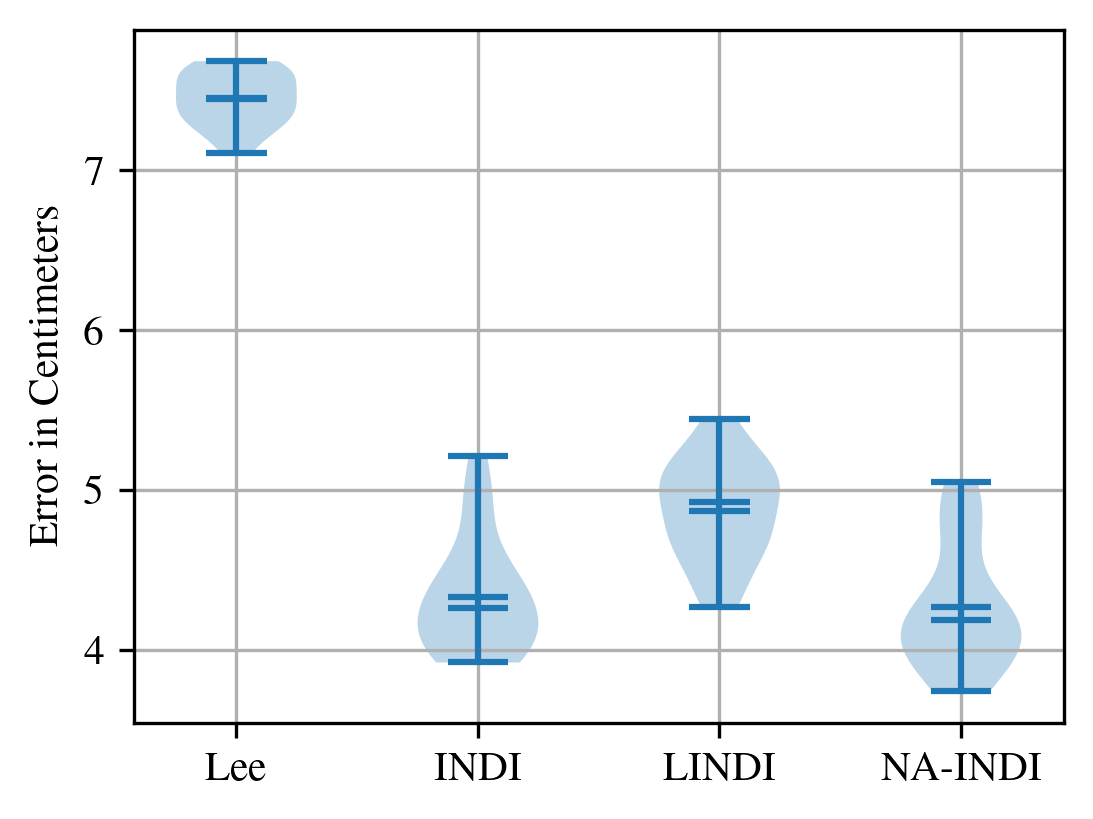

Figure8


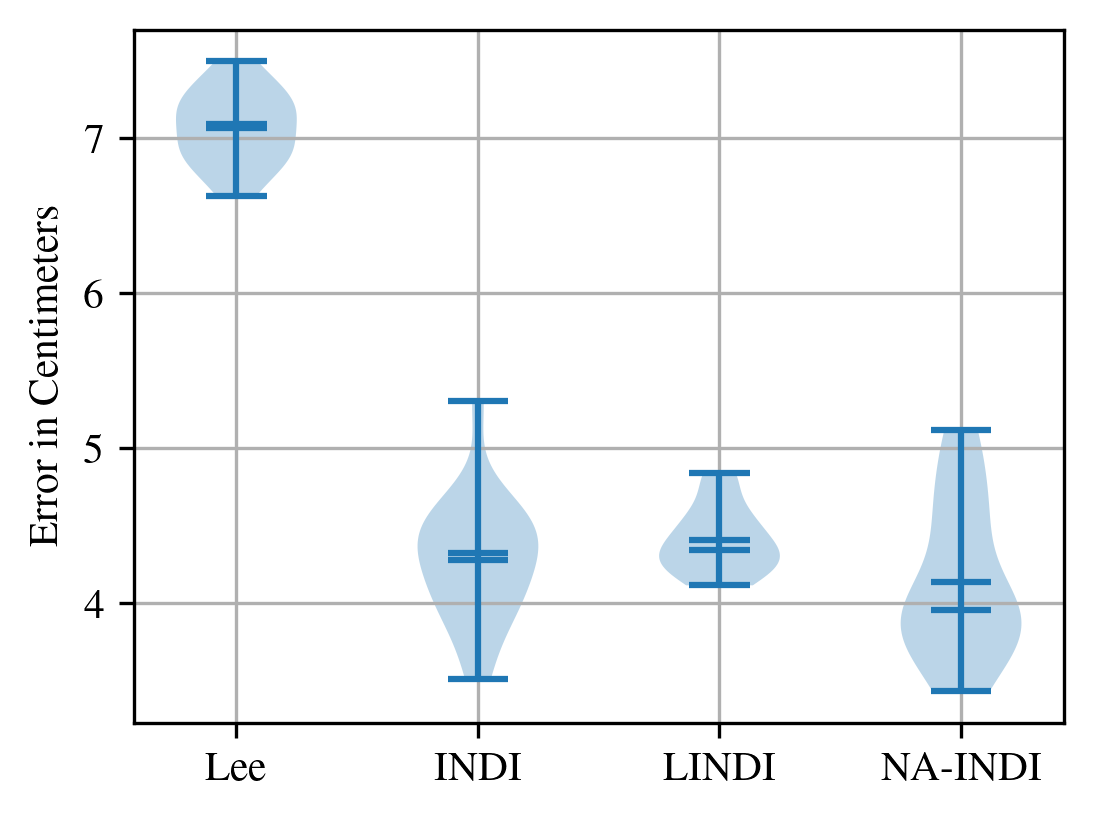

In [41]:
for k in tests.keys():
    data = [es for es in tests[k]["all_error"] if len(es) != 0]
    if len(data) == 4:
        labels = ["Lee", "INDI", "LINDI", "NA-INDI"]
        locations = [1, 2, 3, 4]
    else:
        labels = ["INDI", "LINDI", "NA-INDI"]
        locations = [1, 2, 3]

    plt.figure(figsize=(4, 3), dpi=300)
    plt.violinplot(np.array(data).T*100, showmeans=True, showmedians=True)

    plt.xticks(ticks=locations, labels=labels)
    plt.ylabel("Error in Centimeters")
    plt.grid(True)
    print(k)

    plt.show()

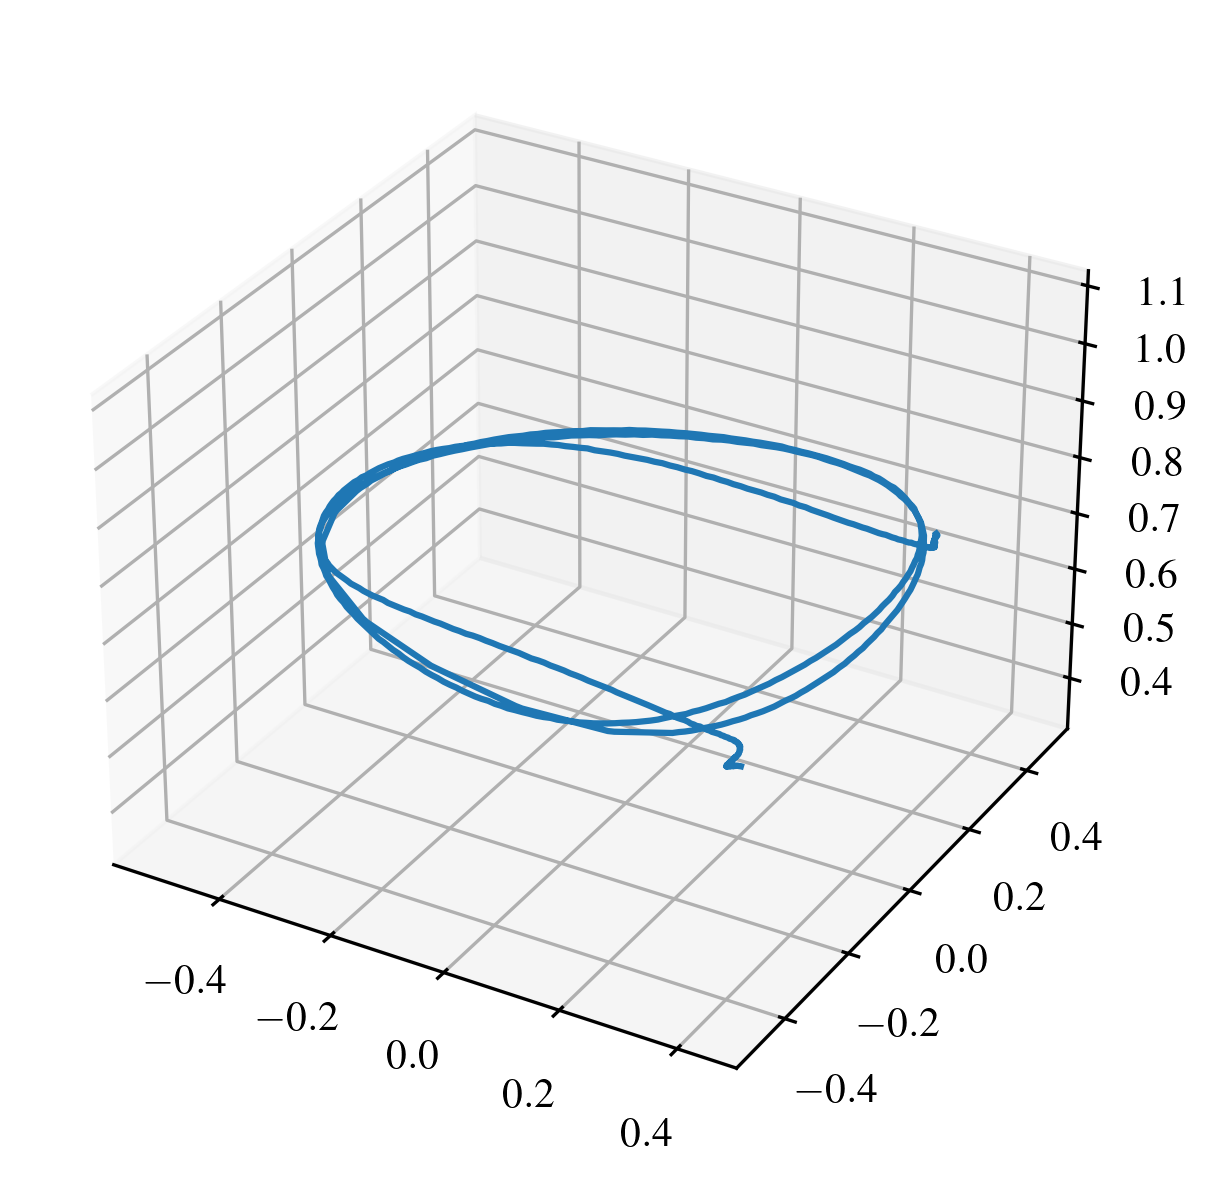

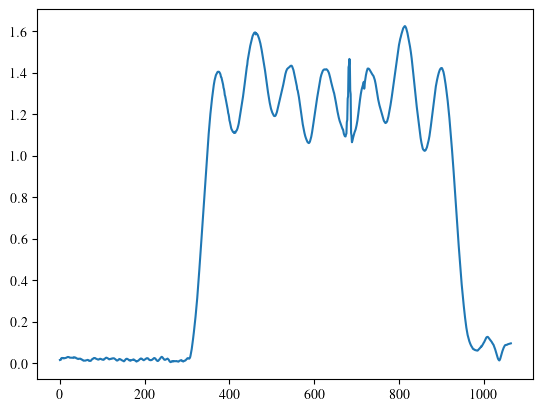

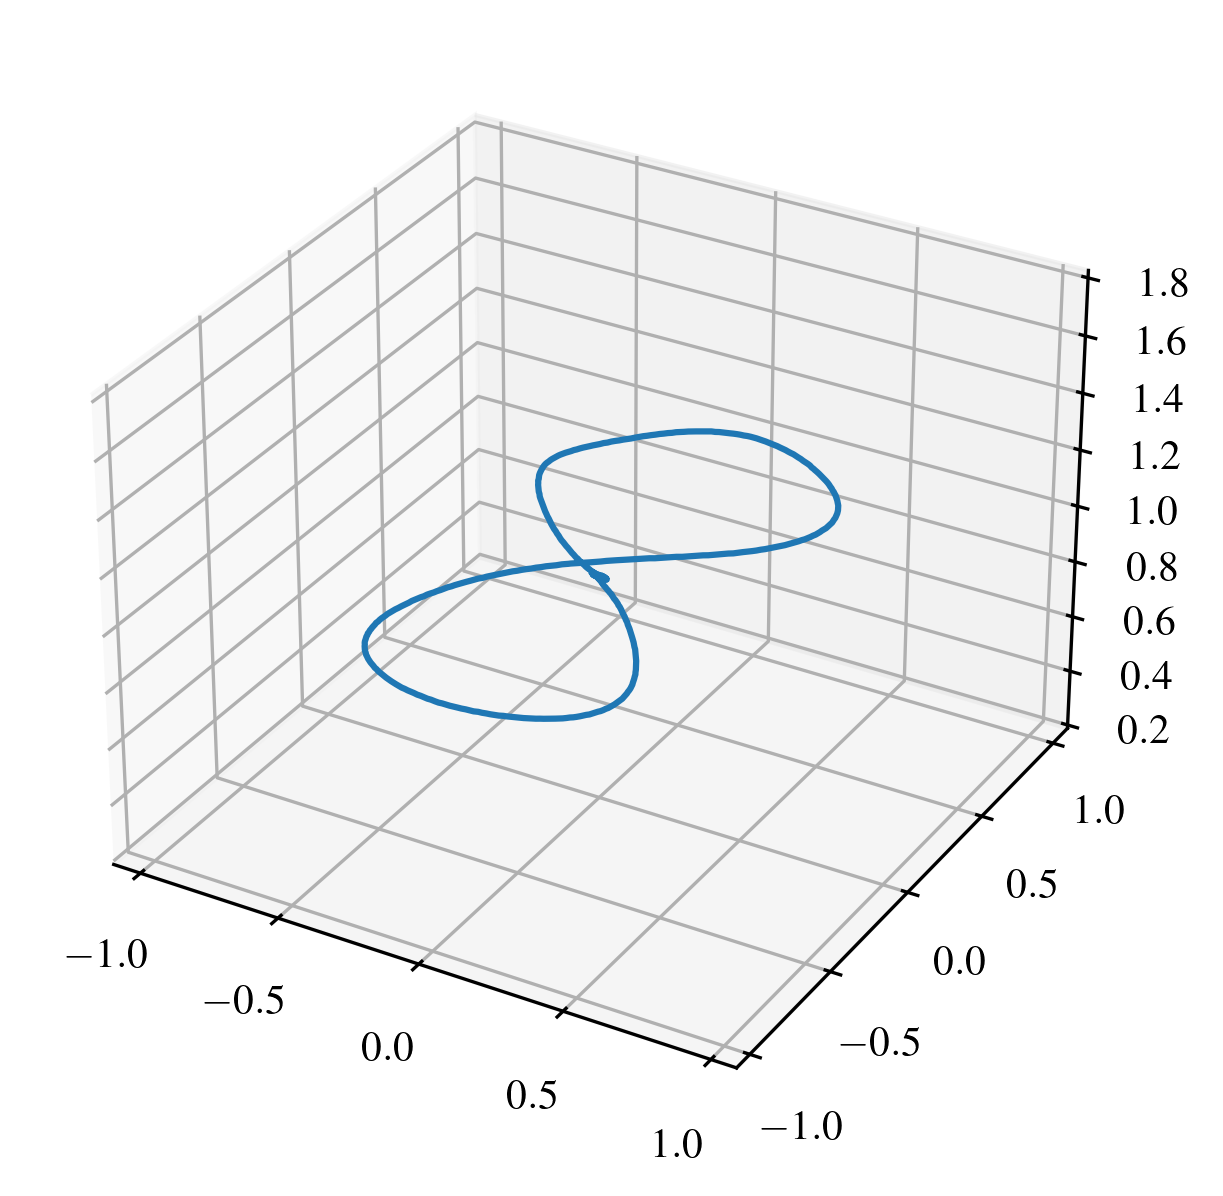

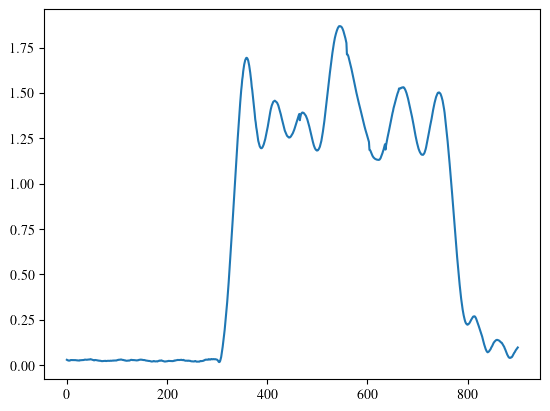

In [42]:
for k, v in tests.items():
    method_path = os.path.join(v["folder"], "indi")
    dp = os.path.join(method_path, os.listdir(method_path)[0])
    
    fig = plt.figure(dpi=300)
    ax = plt.axes(projection='3d')

    data = cfusdlog.decode(dp)['fixedFrequency']

    x = [i for i in data["stateEstimateZ.x"] / 1000]
    y = [i for i in data["stateEstimateZ.y"] / 1000]
    z = [i for i in data["stateEstimateZ.z"] / 1000]
    origin = np.array([x, y, z]).T

    ax.plot3D(x, y, z)

    plt.axis('equal')
    plt.show()
    
    vels = np.array([
        data["stateEstimateZ.vx"],
        data["stateEstimateZ.vy"],
        data["stateEstimateZ.vz"]
    ]).T / 1000
    plt.plot(np.linalg.norm(vels, axis=1))
    plt.show()

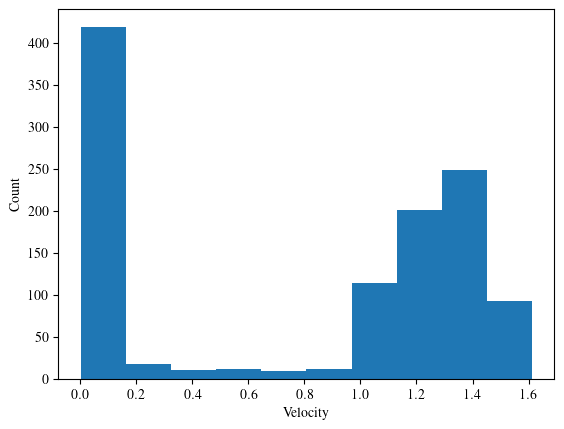

In [43]:
plt.hist(histo_vels, bins=10)
plt.xlabel('Velocity')
plt.ylabel('Count')
plt.show()

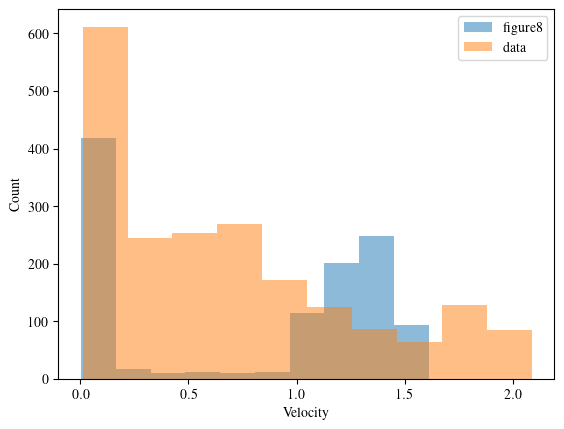

In [66]:
vels2 = []
fol = "../data/single/train_clean"
file_name = np.random.choice(os.listdir(fol))
data = np.load(os.path.join(fol, file_name), allow_pickle=True).item()
v = np.linalg.norm(data["vel"], axis=1)
vels2 = v

plt.hist(histo_vels, bins=10, alpha=.5, label="figure8")
plt.hist(vels2, bins=10, alpha=.5, label="data")
plt.xlabel('Velocity')
plt.ylabel('Count')
plt.legend()
plt.show()